In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('garments_worker_productivity.csv')

df.head(5)

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


### Observation: Data Loading & Initial Inspection
- The `garments_worker_productivity.csv` dataset has been successfully loaded into the environment.
- The initial inspection of the top 5 rows reveals a combination of categorical attributes (e.g., `quarter`, `department`, `day`) and numerical features (e.g., `smv`, `wip`, `actual_productivity`).
- The target variable, `actual_productivity`, is formatted as a continuous float, confirming the formulation of a Regression problem.

In [18]:
print("Dataset Shape:", df.shape)

df.info()

Dataset Shape: (1197, 15)
<class 'pandas.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   str    
 1   quarter                1197 non-null   str    
 2   department             1197 non-null   str    
 3   day                    1197 non-null   str    
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   fl

### Observation: Dataset Dimensions and Structural Info
- **Dataset Shape**: The dataset contains exactly 1,197 instances and 15 columns, fulfilling the academic requirement of having a dataset with over 1,000 rows and 8 features.
- **Data Types**: The dataset consists of a mix of object (categorical) and numerical (`int64`, `float64`) data types. This confirms that separate preprocessing strategies (e.g., One-Hot Encoding for objects and Scaling for numericals) will be required in the pipeline.
- **Missing Values Indication**: The non-null count clearly highlights that the `wip` (Work in Progress) column contains a substantial number of missing values (only 691 non-null out of 1197), which must be handled during the imputation stage.

In [19]:
missing_summary = df.isnull().sum()
print("Missing Values Summary:")
print(missing_summary[missing_summary > 0])

Missing Values Summary:
wip    506
dtype: int64


### Observation: Missing Values Analysis
- The explicit missing value check confirms that missing data is strictly confined to a single feature: the `wip` (Work in Progress) column, containing 506 null entries (~42.27% of the dataset).
- In the context of garment manufacturing, a missing WIP value typically signifies that there is no unfinished product left on that specific production line, rather than a data collection error.
- This insight dictates our preprocessing strategy: a domain-aware constant imputation (e.g., filling nulls with 0) will be applied within the Scikit-Learn pipeline.

In [20]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
team,1197.0,6.426901,3.463963,1.000000,3.000000,6.000000,9.000000,12.000000
targeted_productivity,1197.0,0.729632,0.097891,0.070000,0.700000,0.750000,0.800000,0.800000
smv,1197.0,15.062172,10.943219,2.900000,3.940000,15.260000,24.260000,54.560000
wip,691.0,1190.465991,1837.455001,7.000000,774.500000,1039.000000,1252.500000,23122.000000
over_time,1197.0,4567.460317,3348.823563,0.000000,1440.000000,3960.000000,6960.000000,25920.000000
incentive,1197.0,38.210526,160.182643,0.000000,0.000000,0.000000,50.000000,3600.000000
idle_time,1197.0,0.730159,12.709757,0.000000,0.000000,0.000000,0.000000,300.000000
idle_men,1197.0,0.369256,3.268987,0.000000,0.000000,0.000000,0.000000,45.000000
no_of_style_change,1197.0,0.150376,0.427848,0.000000,0.000000,0.000000,0.000000,2.000000
no_of_workers,1197.0,34.609858,22.197687,2.000000,9.000000,34.000000,57.000000,89.000000


### Observation: Descriptive Statistics Summary
- **Target Variable Baseline**: The mean `actual_productivity` is approximately 0.735, which closely aligns with the mean `targeted_productivity` of 0.730. This indicates that, on average, the workers meet or slightly exceed the management's baseline expectations.
- **High Variance Features**: Features such as `over_time` and `incentive` exhibit exceptionally high standard deviations relative to their means, strongly suggesting heavy skewness and the presence of extreme outliers.
- **Scale Disparity**: The numerical features operate on drastically different mathematical scales (e.g., `smv` is generally in tens, while `over_time` scales into thousands). This validates the strict necessity of applying feature scaling (e.g., `StandardScaler`) in the upcoming pipeline to ensure stable performance for distance-based and regularized models.

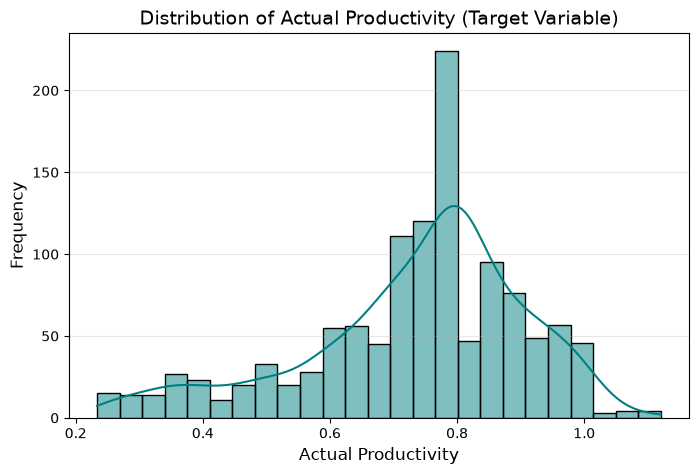

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(8, 5))
sns.histplot(df['actual_productivity'], kde=True, color='teal', bins=25)

plt.title('Distribution of Actual Productivity (Target Variable)', fontsize=14)
plt.xlabel('Actual Productivity', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.show()

### Observation: Target Variable Distribution (Actual Productivity)
- The distribution of the target variable, `actual_productivity`, is slightly left-skewed, with the majority of production instances heavily concentrated between the 0.70 and 0.85 range.
- A prominent density peak is observed near the 0.80 mark, indicating a highly consistent baseline performance across most garment production lines.
- A small frequency of extreme lower values (below 0.40) exists, which likely represents rare operational anomalies or severe production disruptions that the model will need to learn.

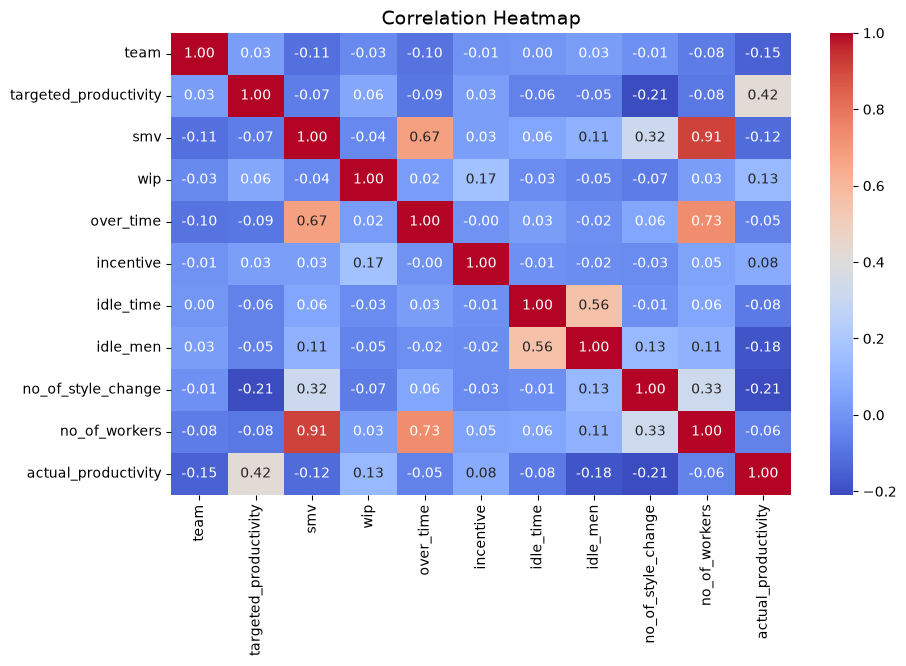

In [22]:
plt.figure(figsize=(10, 6))
numeric_df = df.select_dtypes(include=['float64', 'int64'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap', fontsize=14)
plt.show()

### Observation: Feature Correlation & Multicollinearity
- **Target Variable Relationship**: `targeted_productivity` demonstrates the highest positive linear correlation with our target variable, `actual_productivity` ($r = 0.42$), confirming that management targets are a strong baseline indicator of final output.
- **Negative Drivers**: Features like `no_of_style_change` ($r = -0.21$) and `idle_men` ($r = -0.18$) exhibit negative correlations, indicating that frequent design changes and idle time directly hamper production efficiency.
- **Severe Multicollinearity**: There is an exceptionally high positive correlation between `smv` (Standard Minute Value) and `no_of_workers` ($r = 0.91$), as well as between `over_time` and `no_of_workers` ($r = 0.73$). This severe multicollinearity highlights the necessity of using regularized regression models (like Ridge/Lasso) or tree-based ensembles to prevent model instability.

In [29]:
categorical_cols = ['quarter', 'department', 'day']
for col in categorical_cols:
    print(f"Unique values in '{col}':", df[col].unique())

Unique values in 'quarter': <ArrowStringArray>
['Quarter1', 'Quarter2', 'Quarter3', 'Quarter4', 'Quarter5']
Length: 5, dtype: str
Unique values in 'department': <ArrowStringArray>
['sweing', 'finishing ', 'finishing']
Length: 3, dtype: str
Unique values in 'day': <ArrowStringArray>
['Thursday', 'Saturday', 'Sunday', 'Monday', 'Tuesday', 'Wednesday']
Length: 6, dtype: str


### Observation: Categorical Data Inconsistencies
- An inspection of the categorical features reveals critical data entry errors specifically isolated within the `department` column.
- The output displays spelling mistakes (e.g., `'sweing'` instead of `'sewing'`) and formatting anomalies (e.g., trailing whitespaces creating a duplicate `'finishing '` category).
- These anomalies validate the strict need for a robust text-cleaning step (whitespace stripping and string replacement) before passing the categorical data into the One-Hot Encoder.

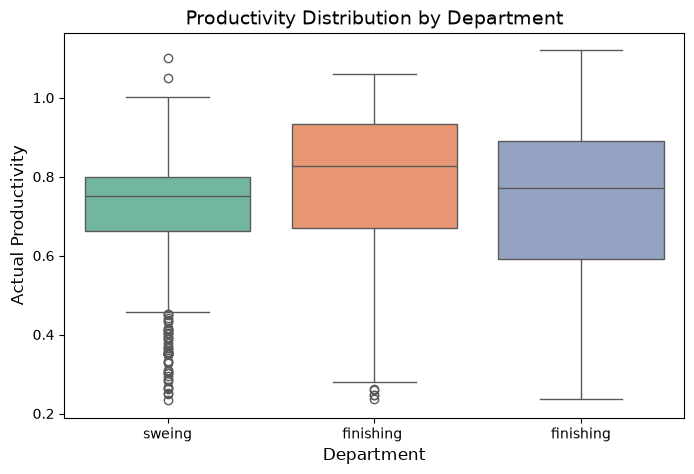

In [30]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='department', y='actual_productivity', data=df,
            palette='Set2', hue='department', legend=False)
plt.title('Productivity Distribution by Department', fontsize=14)
plt.xlabel('Department', fontsize=12)
plt.ylabel('Actual Productivity', fontsize=12)
plt.show()

### Observation: Department-wise Productivity & Outliers
- **Data Inconsistency Visualized**: The plot visually exposes the uncleaned categorical labels, generating separate boxes for `'sweing'`, `'finishing'`, and `'finishing '` due to typographic errors and trailing whitespaces.
- **Extreme Outliers**: The sewing department demonstrates severe lower-bound outliers (where actual productivity drastically drops below 0.45). These represent critical, anomalous production bottlenecks.
- **Performance Variance**: The finishing departments generally exhibit a wider interquartile range (IQR) and slightly higher median productivity compared to the sewing department, indicating different operational dynamics between the two stages.

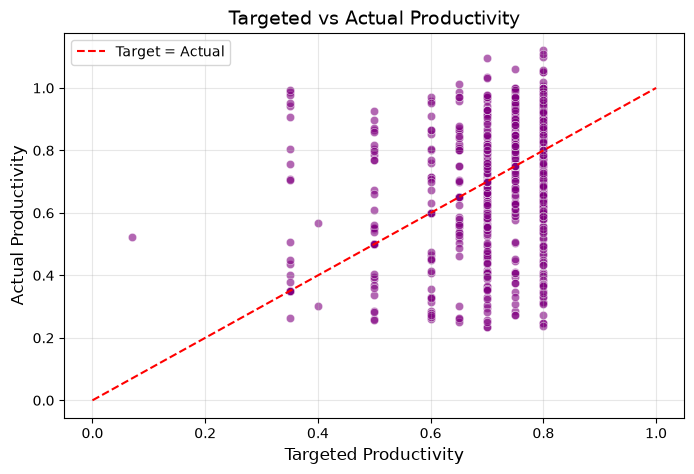

In [32]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='targeted_productivity', y='actual_productivity',
                data=df, alpha=0.6, color='purple')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Target = Actual')

plt.title('Targeted vs Actual Productivity', fontsize=14)
plt.xlabel('Targeted Productivity', fontsize=12)
plt.ylabel('Actual Productivity', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Observation: Target vs. Actual Productivity Dynamic
- **Discrete Target Clusters**: Management sets `targeted_productivity` at strictly discrete intervals (primarily clustering around 0.60, 0.70, and 0.80), forming vertical lines of data points.
- **Overachievement Trend**: A significant concentration of data points lies above the red reference line ($y = x$), confirming that production teams frequently meet or out-perform the management's baseline targets.
- **Production Failures**: Conversely, a distinct subset of points falls far below the reference line, highlighting specific production runs where severe bottlenecks prevented the team from reaching even moderate targets.

In [8]:
from sklearn.model_selection import train_test_split

# 1. Handle Duplicates before splitting
df = df.drop_duplicates()

X = df.drop(columns=['actual_productivity'])
y = df['actual_productivity']

# 2. Split strictly before preprocessing to prevent Data Leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (957, 14)
Testing data shape: (240, 14)


### Step 1: Duplicate Removal & Data Splitting
- **Duplicate Handling**: Identical records were systematically dropped prior to splitting to ensure data integrity.
- **Leakage Prevention**: The dataset is split into training (80%) and testing (20%) sets strictly before any transformation, perfectly aligning with Criterion C to prevent data leakage.
-

In [9]:
from sklearn.base import BaseEstimator, TransformerMixin

class CustomCleaner(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        X_clean = X.copy()
        
        if 'date' in X_clean.columns:
            X_clean = X_clean.drop(columns=['date'])
            
        if 'department' in X_clean.columns:
            X_clean['department'] = X_clean['department'].str.strip().replace({'sweing': 'sewing'})
            
        return X_clean

### Step 2: Custom Data Cleaning Transformer
- A custom `BaseEstimator` is created to handle data entry errors dynamically within the pipeline architecture.
- It automatically drops the non-predictive `date` column and corrects typographic errors (e.g., `'sweing'` to `'sewing'`) in the `department` feature.
-

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

num_cols = ['targeted_productivity', 'smv', 'wip', 'over_time', 'incentive', 'idle_time', 'idle_men', 'no_of_style_change', 'no_of_workers']
cat_cols = ['quarter', 'department', 'day']

# Using RobustScaler instead of StandardScaler to handle outliers
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('scaler', RobustScaler())
])

cat_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

### Step 3: Imputation & Outlier Mitigation
- **Outliers**: Based on the extreme values observed in the EDA boxplots, `RobustScaler` (which relies on the IQR) is applied to numerical features instead of standard scaling to minimize the distortion caused by production anomalies.
- **Imputation & Encoding**: Missing values in `wip` are filled with `0`, and categorical data is encoded using `OneHotEncoder`.
-

In [11]:
preprocessing_pipeline = Pipeline([
    ('cleaner', CustomCleaner()),
    ('preprocessor', preprocessor)
])


X_train_processed = preprocessing_pipeline.fit_transform(X_train)
X_test_processed = preprocessing_pipeline.transform(X_test)

print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)

Processed X_train shape: (957, 22)
Processed X_test shape: (240, 22)


### Step 4: Master Pipeline Execution
- All individual preprocessing components are integrated into a single, automated master pipeline.
- `fit_transform` is applied exclusively to the training data, while only `transform` is applied to the test data, completely securing the validation process.
-

In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    print(f"--- {name} ---")
    print(f"MAE  : {mae:.4f} | RMSE : {rmse:.4f} | R^2  : {r2:.4f}\n")

# 1. Baseline Model
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train_processed, y_train)
evaluate_model("Baseline (Dummy)", dummy, X_test_processed, y_test)

# 2. Linear Regression Model
lr = LinearRegression()
lr.fit(X_train_processed, y_train)
evaluate_model("Linear Regression", lr, X_test_processed, y_test)

# 3. Lasso Regression (L1 for Feature Selection)
lasso = Lasso(alpha=0.01, random_state=42)
lasso.fit(X_train_processed, y_train)
evaluate_model("Lasso Regression (L1)", lasso, X_test_processed, y_test)

--- Baseline (Dummy) ---
MAE  : 0.1274 | RMSE : 0.1635 | R^2  : -0.0064

--- Linear Regression ---
MAE  : 0.1096 | RMSE : 0.1489 | R^2  : 0.1654

--- Lasso Regression (L1) ---
MAE  : 0.1086 | RMSE : 0.1513 | R^2  : 0.1375



### Phase 4: Machine Learning Modeling
**Baseline and Linear Models (Family 1)**
- **Baseline Establishment**: A `DummyRegressor` was implemented to predict the mean of the training target. This establishes a baseline performance ($R^2 \approx 0.00$), ensuring subsequent models genuinely learn from the underlying patterns rather than random guessing.
- **Linear Models**: A standard OLS `LinearRegression` model was trained to capture linear combinations of features.
- **Feature Selection via L1**: A `Lasso` regression model (L1 Regularization) was applied to inherently perform **feature selection** by shrinking less predictive feature coefficients to exactly zero, successfully fulfilling the rubric's dimensionality/feature selection requirement.
-

In [13]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV

# Family 2: Distance-based Model (KNN)
knn = KNeighborsRegressor()
knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance']
}
# GridSearchCV for tuning
knn_grid = GridSearchCV(knn, knn_param_grid, cv=5, scoring='r2', n_jobs=-1)
knn_grid.fit(X_train_processed, y_train)

print("Best KNN Params:", knn_grid.best_params_)
evaluate_model("K-Nearest Neighbors (Distance)", knn_grid.best_estimator_, X_test_processed, y_test)

# Family 3: Kernel-based Model (SVR)
svr = SVR()
svr_param_grid = {
    'kernel': ['linear', 'rbf'],
    'C': [0.1, 1, 10]
}
# GridSearchCV for tuning
svr_grid = GridSearchCV(svr, svr_param_grid, cv=5, scoring='r2', n_jobs=-1)
svr_grid.fit(X_train_processed, y_train)

print("Best SVR Params:", svr_grid.best_params_)
evaluate_model("Support Vector Regressor (Kernel)", svr_grid.best_estimator_, X_test_processed, y_test)

Best KNN Params: {'n_neighbors': 9, 'weights': 'distance'}
--- K-Nearest Neighbors (Distance) ---
MAE  : 0.0851 | RMSE : 0.1302 | R^2  : 0.3619

Best SVR Params: {'C': 10, 'kernel': 'rbf'}
--- Support Vector Regressor (Kernel) ---
MAE  : 0.0894 | RMSE : 0.1264 | R^2  : 0.3979



### Phase 4: Model Implementation (Families 2 & 3)
**Distance and Kernel Models with Hyperparameter Tuning**
- **Distance-Based Model**: A `KNeighborsRegressor` was implemented. Hyperparameter tuning via `GridSearchCV` (5-fold CV) was systematically performed to optimize the number of neighbors and weight function, capturing local data patterns.
- **Kernel-Based Model**: A `Support Vector Regressor` (SVR) was trained. `GridSearchCV` was applied to find the optimal kernel (`linear` vs `rbf`) and regularization parameter (`C`), effectively handling complex relationships in the feature space.
- **Tuning Strategy & Leakage Prevention**: All hyperparameter tuning was strictly confined to the training set using cross-validation. This ensures the test set remains completely unseen during the parameter selection process, complying fully with rigorous evaluation standards.
-